# 03 - Centralities (Panama Papers)

**Question.** Who structures the offshore network? This notebook ranks nodes by degree centrality, PageRank and betweenness, on the bipartite graph and on the entity projection, then reads those ranks against jurisdictions.

**Graphs.** Built by `src/run_stats.py` and described in notebooks 01 and 02.
- Bipartite graph: entities on one side, officers, intermediaries and addresses on the other. Undirected, unweighted.
- Entity projection: two entities are linked when they share a connector under the cap (officers 500, intermediaries 50, addresses 50). The weight is the number of shared connectors. Centralities for entities on this graph are computed on its largest connected component. The giant intermediaries are not nodes of the projection: a connector above the cap creates no edge.

**Normalization.** Degree centrality is `degree / (n - 1)` on the graph where it is computed. PageRank uses damping 0.85. `pagerank_x_n = PageRank × n` is 1 for a node with the average score. Betweenness is normalized. It is estimated with Brandes sampling because an exact run is a shortest-path tree from every node: the bipartite giant component has about 311,000 nodes, which is the same reason notebook 02 did not compute all-pairs distances there. Sampling uses `seed=0`, `k=50` sources on the bipartite giant component and `k=200` on the projection component. Weight is not used as a length. A larger projection weight is a stronger tie, not a longer path, so betweenness stays in hops. PageRank on the projection does use the weight as a strength.

In [1]:
from pathlib import Path
import sys, json, pickle
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.load import load_panama, PROC
from src.import_neo4j import credentials

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_colwidth", 70)
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

ALPHA = 0.85
K_BIP = 50
K_PROJ = 200
SEED = 0

nodes, _rels = load_panama()
B, P = pickle.load(open(PROC / "graphs.pkl", "rb"))
meta = nodes.set_index("node_id")
print(f"networkx {nx.__version__}")
print(f"bipartite  {B.number_of_nodes():,} nodes, {B.number_of_edges():,} edges")
print(f"projection {P.number_of_nodes():,} nodes, {P.number_of_edges():,} edges")

def short(s, n=36):
    s = "" if pd.isna(s) else str(s)
    return s if len(s) <= n else s[: n - 1] + "…"

def pretty(df, sci=("pagerank", "betweenness")):
    out = df.copy()
    for c in df.columns:
        if not pd.api.types.is_float_dtype(df[c]):
            continue
        out[c] = df[c].map(lambda v: "" if pd.isna(v) else (f"{v:.3e}" if c in sci else f"{v:.4f}"))
    return out

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()

def jaccard(df, a, b, k):
    left, right = set(df.nlargest(k, a).index), set(df.nlargest(k, b).index)
    return len(left & right) / len(left | right)

networkx 3.3
bipartite  468,623 nodes, 511,687 edges
projection 213,634 nodes, 1,238,967 edges


## 1. Degree centrality on the bipartite graph

Degree is the number of neighbors. Degree centrality divides by `n - 1`, with `n` the number of nodes in the bipartite graph, so the three kinds of actor are on the same scale. An intermediary's degree is the number of entities it serves. The same for an officer. An entity's degree is the number of officers, intermediaries and addresses it is linked to.

Degree centrality uses n - 1 = 468,622.
Actors in the graph: 14,074 intermediaries, 238,078 officers, 213,634 entities.
Highest-degree intermediaries


,name,countries,degree,degree_centrality
11001746,ORION HOUSE SERVICES (HK) LIMITED,Hong Kong,7016,0.0150
11011863,MOSSACK FONSECA & CO.,Panama,4364,0.0093
11012037,PRIME CORPORATE SOLUTIONS SARL,Luxembourg,4117,0.0088
11001708,OFFSHORE BUSINESS CONSULTANT (INT'L) LIMITED,Hong Kong,4094,0.0087
11008027,MOSSACK FONSECA & CO. (SINGAPORE) PTE LTD.,Singapore,3888,0.0083
11009351,CONSULCO INTERNATIONAL LIMITED,United Arab Emirates;Cyprus,3168,0.0068
11007372,MOSSACK FONSECA & CO. (GENEVA) S.A.,Switzerland,2986,0.0064
11011539,MOSSACK FONSECA & CO. (U.K.) LIMITED,United Kingdom,2538,0.0054
11009139,MOSSACK FONSECA & CO. (PERU) CORP.,Peru,2055,0.0044
11009218,"POWER POINT INT'L CO., LTD.",Taiwan,2045,0.0044


Highest-degree officers


,name,countries,degree,degree_centrality
12160432,MOSSFON SUBSCRIBERS LTD.,Samoa,3882,0.0083
12172849,FIRST SHAREHOLDERS LIMITED,Samoa,368,0.0008
12204607,BOS NOMINEES (JERSEY) LIMITED,Jersey,343,0.0007
12204608,BOS SECRETARIES (JERSEY) LIMITED,Jersey,329,0.0007
12202037,CONSTANT LTD.,Seychelles,316,0.0007
12202038,CUSTODIAN LTD.,Seychelles,301,0.0006
12162249,Dorchester International Inc,Saint Kitts and Nevis,265,0.0006
12154939,BROCK NOMINEES LIMITED,Guernsey,242,0.0005
12154938,TENBY NOMINEES LIMITED,Guernsey,218,0.0005
12013188,BURNHAM LIMITED,Anguilla,200,0.0004


Highest-degree entities


,name,jurisdiction,degree,degree_centrality
10200346,ACCELONIC LTD.,British Virgin Islands,1007,0.0021
10103570,VELA GAS INVESTMENTS LTD.,British Virgin Islands,493,0.0011
10133161,Dale Capital Group Limited,British Virgin Islands,448,0.0010
10154669,MAGN DEVELOPMENT LIMITED,British Virgin Islands,248,0.0005
10126705,DigiWin Systems Group Holding Limited,British Virgin Islands,210,0.0004
10025005,GNG LTD.,Seychelles,202,0.0004
10079552,BOB AGENTS LIMITED,British Virgin Islands,172,0.0004
10059536,INGELSA LTD.,British Virgin Islands,168,0.0004
10204952,ROCKOVER RESOURCES LIMITED,British Virgin Islands,167,0.0004
10202064,LUK FOOK (CONTROL) LIMITED,British Virgin Islands,156,0.0003


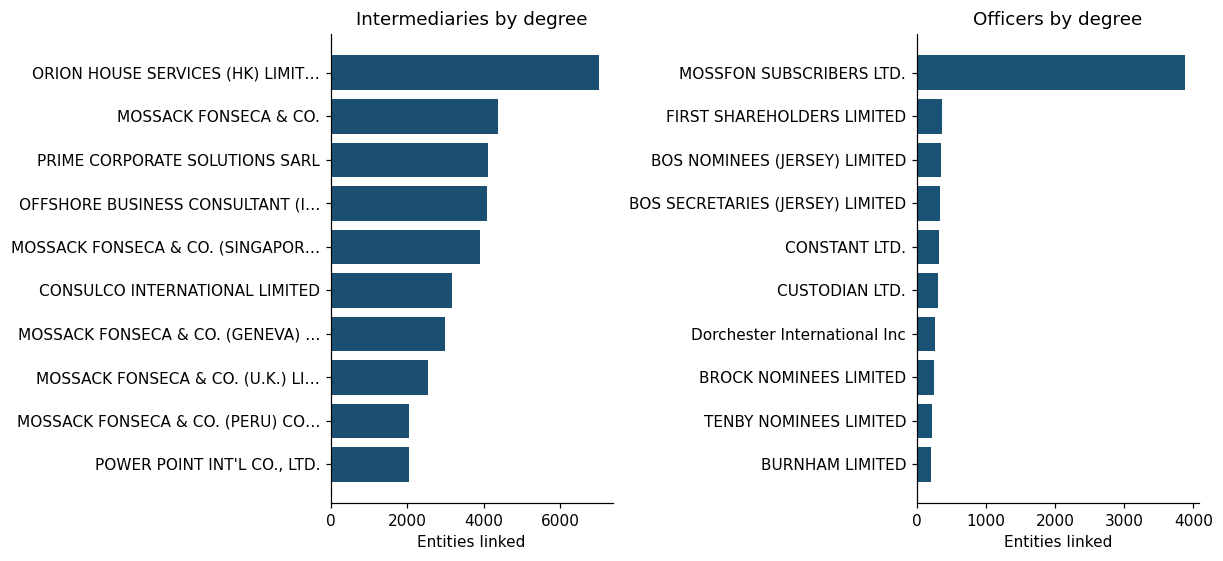

In [2]:
nB = B.number_of_nodes()
degB = pd.Series(dict(B.degree()), dtype=float)
centB = degB / (nB - 1)

def actor_frame(kind):
    idx = meta.index[meta.kind.eq(kind)].intersection(degB.index)
    df = meta.loc[idx, ["name", "countries", "jurisdiction_description"]].copy()
    df = df.rename(columns={"jurisdiction_description": "jurisdiction"})
    df["degree"] = degB.reindex(df.index).astype(int)
    df["degree_centrality"] = centB.reindex(df.index)
    return df

inter = actor_frame("intermediary")
off = actor_frame("officer")
entB = actor_frame("entity")

def show_top(df, k, cols):
    display(pretty(df.nlargest(k, "degree")[cols], sci=()))

print(f"Degree centrality uses n - 1 = {nB - 1:,}.")
print(f"Actors in the graph: {len(inter):,} intermediaries, {len(off):,} officers, {len(entB):,} entities.")
print("Highest-degree intermediaries")
show_top(inter, 12, ["name", "countries", "degree", "degree_centrality"])
print("Highest-degree officers")
show_top(off, 12, ["name", "countries", "degree", "degree_centrality"])
print("Highest-degree entities")
show_top(entB, 12, ["name", "jurisdiction", "degree", "degree_centrality"])

fig, axes = plt.subplots(1, 2, figsize=(11.2, 5.2))
for ax, df, title, color in (
    (axes[0], inter, "Intermediaries by degree", "#1b4f72"),
    (axes[1], off, "Officers by degree", "#1a5276"),
):
    top = df.nlargest(10, "degree").iloc[::-1]
    ax.barh(top["name"].map(lambda s: short(s, 32)), top["degree"], color=color)
    ax.set_xlabel("Entities linked")
    ax.set_title(title)
savefig("03_degree_intermediaries_officers.png")

## 2. PageRank on the bipartite graph

PageRank is the long-run share of a random walk that restarts with probability `1 - 0.85`. It is exact on the full bipartite graph. A node with many well-connected neighbors scores above a node that only has many leaves.

Spearman correlation on intermediaries:
  degree vs pagerank: rho = 0.922 (p = 0.00e+00)
Top-15 Jaccard, intermediary degree ∩ PageRank = 1.00
Top-15 Jaccard, officer degree ∩ PageRank = 0.67
Top-15 Jaccard, entity degree ∩ PageRank = 0.76
Highest PageRank intermediaries


,name,countries,degree,degree_centrality,pagerank,pagerank_x_n
11001746,ORION HOUSE SERVICES (HK) LIMITED,Hong Kong,7016,0.0150,5.767e-03,2702.5527
11001708,OFFSHORE BUSINESS CONSULTANT (INT'L) LIMITED,Hong Kong,4094,0.0087,3.923e-03,1838.5857
11008027,MOSSACK FONSECA & CO. (SINGAPORE) PTE LTD.,Singapore,3888,0.0083,3.276e-03,1535.0597
11012037,PRIME CORPORATE SOLUTIONS SARL,Luxembourg,4117,0.0088,2.867e-03,1343.4888
11009139,MOSSACK FONSECA & CO. (PERU) CORP.,Peru,2055,0.0044,1.920e-03,899.8944
11011863,MOSSACK FONSECA & CO.,Panama,4364,0.0093,1.894e-03,887.3898
11011539,MOSSACK FONSECA & CO. (U.K.) LIMITED,United Kingdom,2538,0.0054,1.778e-03,832.9976
11009351,CONSULCO INTERNATIONAL LIMITED,United Arab Emirates;Cyprus,3168,0.0068,1.563e-03,732.3273
11010643,LEGAL CONSULTING SERVICES LIMITED,Russia,2014,0.0043,1.502e-03,703.6544
11012290,MOSSFON MANAGERS LTD.,Bahamas,1871,0.0040,1.464e-03,686.0732


Highest PageRank officers


,name,countries,degree,pagerank,pagerank_x_n
12160432,MOSSFON SUBSCRIBERS LTD.,Samoa,3882,2.566e-03,1202.6213
12154939,BROCK NOMINEES LIMITED,Guernsey,242,1.210e-04,56.7027
12162249,Dorchester International Inc,Saint Kitts and Nevis,265,1.103e-04,51.6861
12217281,MOSTALINA INVESTMENTS S.A,Seychelles,118,1.096e-04,51.3423
12154938,TENBY NOMINEES LIMITED,Guernsey,218,1.072e-04,50.2371
12174016,BROTHERHOOD FOUNDATION,Panama,157,1.055e-04,49.4310
12172849,FIRST SHAREHOLDERS LIMITED,Samoa,368,1.054e-04,49.3959
12204607,BOS NOMINEES (JERSEY) LIMITED,Jersey,343,1.036e-04,48.5658


Highest PageRank entities


,name,jurisdiction,degree,pagerank,pagerank_x_n
10200346,ACCELONIC LTD.,British Virgin Islands,1007,4.743e-04,222.2488
10103570,VELA GAS INVESTMENTS LTD.,British Virgin Islands,493,2.340e-04,109.6441
10133161,Dale Capital Group Limited,British Virgin Islands,448,2.107e-04,98.7571
10154669,MAGN DEVELOPMENT LIMITED,British Virgin Islands,248,1.172e-04,54.9385
10126705,DigiWin Systems Group Holding Limited,British Virgin Islands,210,1.006e-04,47.1516
10025005,GNG LTD.,Seychelles,202,9.643e-05,45.1893
10079552,BOB AGENTS LIMITED,British Virgin Islands,172,8.297e-05,38.8834
10059536,INGELSA LTD.,British Virgin Islands,168,8.106e-05,37.9859
10204952,ROCKOVER RESOURCES LIMITED,British Virgin Islands,167,7.978e-05,37.3878
10130122,AsiaStar Telecom Limited,British Virgin Islands,154,7.428e-05,34.8096


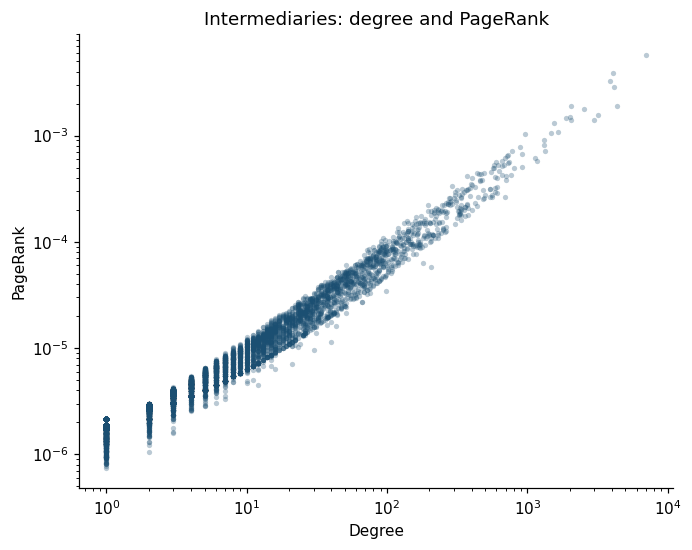

In [3]:
prB = nx.pagerank(B, alpha=ALPHA, tol=1e-6)
for df in (inter, off, entB):
    df["pagerank"] = df.index.map(prB)
    df["pagerank_x_n"] = df["pagerank"] * nB

print("Spearman correlation on intermediaries:")
for a, b in (("degree", "pagerank"),):
    rho, pval = spearmanr(inter[a], inter[b])
    print(f"  {a} vs {b}: rho = {rho:.3f} (p = {pval:.2e})")
print(f"Top-15 Jaccard, intermediary degree ∩ PageRank = {jaccard(inter, 'degree', 'pagerank', 15):.2f}")
print(f"Top-15 Jaccard, officer degree ∩ PageRank = {jaccard(off, 'degree', 'pagerank', 15):.2f}")
print(f"Top-15 Jaccard, entity degree ∩ PageRank = {jaccard(entB, 'degree', 'pagerank', 15):.2f}")

print("Highest PageRank intermediaries")
display(pretty(inter.nlargest(10, "pagerank")[["name", "countries", "degree", "degree_centrality", "pagerank", "pagerank_x_n"]]))
print("Highest PageRank officers")
display(pretty(off.nlargest(8, "pagerank")[["name", "countries", "degree", "pagerank", "pagerank_x_n"]]))
print("Highest PageRank entities")
display(pretty(entB.nlargest(10, "pagerank")[["name", "jurisdiction", "degree", "pagerank", "pagerank_x_n"]]))

fig, ax = plt.subplots(figsize=(6.4, 5.1))
ax.scatter(inter["degree"], inter["pagerank"], s=12, alpha=0.3, c="#1b4f72", linewidths=0)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Degree")
ax.set_ylabel("PageRank")
ax.set_title("Intermediaries: degree and PageRank")
savefig("03_intermediary_degree_pagerank.png")

## 3. Betweenness on the bipartite giant component

Betweenness is the share of shortest paths that pass through a node. Exact betweenness from all 311,000 nodes of the giant component is not practical in NetworkX (each source is a full traversal). The estimate uses 50 random sources, `seed=0`, and NetworkX rescales the sample so the scores are on the same scale as exact normalized betweenness. Fifty sources are 50 / 310,904 of the component, about 0.016%. The top of the list is the part that can be read. Small gaps between mid-ranked nodes are sampling noise.

Nodes outside the giant component have no estimate.

In [4]:
import time
t = time.time()
giant = max(nx.connected_components(B), key=len)
bcB = nx.betweenness_centrality(B.subgraph(giant), k=K_BIP, normalized=True, seed=SEED)
print(f"Giant component {len(giant):,} nodes ({len(giant) / nB:.1%}).")
print(f"Betweenness k={K_BIP} ({K_BIP / len(giant):.3%} of sources) in {time.time() - t:.0f}s.")
for df in (inter, off, entB):
    df["betweenness"] = df.index.map(bcB)

scored = inter.dropna(subset=["betweenness"])
rho_db, p_db = spearmanr(scored["degree"], scored["betweenness"])
rho_pb, p_pb = spearmanr(scored["pagerank"], scored["betweenness"])
print(f"Intermediaries with an estimate: {len(scored):,} / {len(inter):,}")
print(f"Spearman degree vs betweenness: rho = {rho_db:.3f}")
print(f"Spearman PageRank vs betweenness: rho = {rho_pb:.3f}")
print(f"Top-15 Jaccard degree ∩ betweenness = {jaccard(inter, 'degree', 'betweenness', 15):.2f}")
print(f"Top-15 Jaccard PageRank ∩ betweenness = {jaccard(inter, 'pagerank', 'betweenness', 15):.2f}")

cols = ["name", "countries", "degree", "pagerank", "betweenness"]
print("Highest betweenness intermediaries")
display(pretty(inter.nlargest(10, "betweenness")[cols]))
print("Highest betweenness officers")
display(pretty(off.nlargest(8, "betweenness")[cols]))

Giant component 310,904 nodes (66.3%).
Betweenness k=50 (0.016% of sources) in 71s.


Intermediaries with an estimate: 1,762 / 14,074
Spearman degree vs betweenness: rho = 0.965
Spearman PageRank vs betweenness: rho = 0.968
Top-15 Jaccard degree ∩ betweenness = 0.43
Top-15 Jaccard PageRank ∩ betweenness = 0.43
Highest betweenness intermediaries


,name,countries,degree,pagerank,betweenness
11008027,MOSSACK FONSECA & CO. (SINGAPORE) PTE LTD.,Singapore,3888,3.276e-03,1.496e-01
11011539,MOSSACK FONSECA & CO. (U.K.) LIMITED,United Kingdom,2538,1.778e-03,1.353e-01
11001746,ORION HOUSE SERVICES (HK) LIMITED,Hong Kong,7016,5.767e-03,9.774e-02
11000044,HORIZON INVESTMENT SA,Switzerland,540,3.145e-04,8.849e-02
11011863,MOSSACK FONSECA & CO.,Panama,4364,1.894e-03,7.984e-02
11001708,OFFSHORE BUSINESS CONSULTANT (INT'L) LIMITED,Hong Kong,4094,3.923e-03,7.836e-02
11012037,PRIME CORPORATE SOLUTIONS SARL,Luxembourg,4117,2.867e-03,7.424e-02
11010643,LEGAL CONSULTING SERVICES LIMITED,Russia,2014,1.502e-03,5.796e-02
11012146,OMNI MANAGEMENT CONSULTANCY FZE,Cyprus,1315,8.095e-04,5.230e-02
11000489,GOLDSTAR EQUITY LTD,Latvia,1335,7.215e-04,4.536e-02


Highest betweenness officers


,name,countries,degree,pagerank,betweenness
12160432,MOSSFON SUBSCRIBERS LTD.,Samoa,3882,2.566e-03,6.983e-01
12202004,HATHERLEY LIMITED,Seychelles,72,4.592e-05,4.745e-02
12164007,SOLIDARITY ALLIANCE FOUNDATION,Panama,99,6.717e-05,4.492e-02
12177701,CHARITABLE AND GOODWILL FOUNDATION,Panama,45,2.349e-05,4.322e-02
12202038,CUSTODIAN LTD.,Seychelles,301,1.033e-04,3.544e-02
13009325,MAHMOOD PASHA,United Arab Emirates,2,1.816e-06,3.047e-02
12174016,BROTHERHOOD FOUNDATION,Panama,157,1.055e-04,2.756e-02
12118441,TRIDENT OVERSEAS MANAGEMENT LTD.,Belize,88,3.363e-05,2.747e-02


## 4. The same three scores on the entity projection

Only entities have a score here. Degree is the number of other entities that share a kept connector. PageRank uses the edge weight. Betweenness uses hops and 200 sampled sources out of the component (about 0.75% of its nodes). The component is the largest one. The other components are tiny or are isolated entities, and betweenness is not defined across components.

In [5]:
lcc = max(nx.connected_components(P), key=len)
H = P.subgraph(lcc).copy()
nH = H.number_of_nodes()
print(f"Projection giant component: {nH:,} nodes, {H.number_of_edges():,} edges ({nH / P.number_of_nodes():.1%} of entities).")

t = time.time()
prH = nx.pagerank(H, alpha=ALPHA, weight="weight", tol=1e-6)
print(f"PageRank {time.time() - t:.1f}s")
t = time.time()
bcH = nx.betweenness_centrality(H, k=K_PROJ, normalized=True, seed=SEED)
print(f"Betweenness k={K_PROJ} ({K_PROJ / nH:.2%} of sources) in {time.time() - t:.0f}s")

proj = meta.loc[list(H.nodes), ["name", "jurisdiction_description"]].copy()
proj = proj.rename(columns={"jurisdiction_description": "jurisdiction"})
proj["degree"] = pd.Series(dict(H.degree()), dtype=int)
proj["strength"] = pd.Series(dict(H.degree(weight="weight")), dtype=float)
proj["degree_centrality"] = proj["degree"] / (nH - 1)
proj["pagerank"] = pd.Series(prH)
proj["pagerank_x_n"] = proj["pagerank"] * nH
proj["betweenness"] = pd.Series(bcH)

print("Spearman, entities in the projection component:")
for a, b in (("degree", "pagerank"), ("strength", "pagerank"), ("degree", "betweenness"), ("pagerank", "betweenness")):
    rho, pval = spearmanr(proj[a], proj[b])
    print(f"  {a} vs {b}: rho = {rho:.3f}")
print(f"Top-20 Jaccard strength ∩ PageRank = {jaccard(proj, 'strength', 'pagerank', 20):.2f}")
print(f"Top-20 Jaccard PageRank ∩ betweenness = {jaccard(proj, 'pagerank', 'betweenness', 20):.2f}")

pcols = ["name", "jurisdiction", "degree", "strength", "degree_centrality", "pagerank", "betweenness"]
print("Highest PageRank entities in the projection")
display(pretty(proj.nlargest(12, "pagerank")[pcols]))
print("Highest betweenness entities in the projection")
display(pretty(proj.nlargest(8, "betweenness")[pcols]))
print("Jurisdictions of the 20 highest-PageRank projection entities:")
print(proj.nlargest(20, "pagerank")["jurisdiction"].value_counts().to_string())

Projection giant component: 26,643 nodes, 831,726 edges (12.5% of entities).


PageRank 0.5s


Betweenness k=200 (0.75% of sources) in 23s


Spearman, entities in the projection component:
  degree vs pagerank: rho = 0.604
  strength vs pagerank: rho = 0.650
  degree vs betweenness: rho = 0.223
  pagerank vs betweenness: rho = 0.542
Top-20 Jaccard strength ∩ PageRank = 0.00
Top-20 Jaccard PageRank ∩ betweenness = 0.03
Highest PageRank entities in the projection


,name,jurisdiction,degree,strength,degree_centrality,pagerank,betweenness
node_id,,,,,,,
10070826,DTL HOLDING INC.,British Virgin Islands,257,259.0000,0.0096,1.239e-04,1.279e-02
10174478,FOLLET CORPORATION,Bahamas,37,54.0000,0.0014,1.189e-04,1.820e-04
10174926,ICELAND MANAGEMENT LTD.,Bahamas,37,54.0000,0.0014,1.189e-04,1.820e-04
10185747,ALPINE INVESTMENTS LTD.,Bahamas,67,84.0000,0.0025,1.148e-04,1.570e-03
10183063,LOVENA INVESTMENTS LIMITED,Bahamas,288,405.0000,0.0108,1.138e-04,2.543e-02
10181950,DAGAMA INVESTMENTS LIMITED,Bahamas,82,98.0000,0.0031,1.124e-04,1.712e-03
10186098,ADVANTAGE POINT S.A.,Bahamas,142,187.0000,0.0053,1.118e-04,2.582e-03
10191616,WITACO LIMITED,Seychelles,189,219.0000,0.0071,1.101e-04,5.759e-03
10144685,Auckland Development Limited,British Virgin Islands,128,179.0000,0.0048,1.076e-04,5.611e-03


Highest betweenness entities in the projection


,name,jurisdiction,degree,strength,degree_centrality,pagerank,betweenness
node_id,,,,,,,
10125889,NORDY ASSOCIATES LIMITED,British Virgin Islands,214,356.0000,0.0080,6.865e-05,7.608e-02
10145760,TRUCK RESOURCES LIMITED,Hong Kong,84,84.0000,0.0032,5.745e-05,6.635e-02
10139420,FERROSCALE LIMITED,Hong Kong,110,110.0000,0.0041,7.042e-05,5.722e-02
10096511,HAWKSEYE INTERNATIONAL LIMITED,British Virgin Islands,541,865.0000,0.0203,9.164e-05,5.623e-02
10132634,RODIN DEVELOPMENT LIMITED,British Virgin Islands,327,327.0000,0.0123,4.960e-05,5.612e-02
10141187,PALACE HOUSE TURF CLUB LIMITED,Hong Kong,136,136.0000,0.0051,8.023e-05,4.802e-02
10066623,RIDGELEY ENTERPRISES LIMITED,British Virgin Islands,191,191.0000,0.0072,8.093e-05,4.735e-02
10115105,GLOBAL GOLD MINING LIMITED,British Virgin Islands,15,15.0000,0.0006,3.624e-05,4.657e-02


Jurisdictions of the 20 highest-PageRank projection entities:
jurisdiction
Bahamas                   10
British Virgin Islands     8
Seychelles                 1
Panama                     1


## 5. Bipartite graph against the projection, and jurisdictions

An entity can be central in the bipartite graph because it has many direct connectors, and central in the projection because it shares those connectors with many other entities. The two are not the same list. Jurisdictions are not nodes. A jurisdiction is summarized by how many entities it has, and by the sum of those entities' bipartite degrees (how many connector links sit in that jurisdiction).

Entities in the projection giant component: 26,643 / 213,634
Overlap of the top 20 PageRank entities, bipartite ∩ projection: 0 / 20
Overlap of top 20 bipartite degree ∩ top 20 projection strength: 0 / 20
Spearman, entities in the component: bipartite PageRank vs projection PageRank = 0.079
Spearman, bipartite degree vs projection strength = 0.044
Jurisdictions by number of entities


,jurisdiction,entities,degree_sum,degree_mean,share_of_entities,share_of_degree
0,British Virgin Islands,113648,287153,2.5267,0.5320,0.5612
1,Panama,48360,109971,2.2740,0.2264,0.2149
2,Bahamas,15915,30518,1.9176,0.0745,0.0596
3,Seychelles,15182,39946,2.6311,0.0711,0.0781
4,Niue,9611,13243,1.3779,0.0450,0.0259
5,Samoa,5307,17793,3.3527,0.0248,0.0348
6,British Anguilla,3253,7268,2.2342,0.0152,0.0142
7,Nevada,1260,2828,2.2444,0.0059,0.0055
8,Hong Kong,452,1183,2.6173,0.0021,0.0023
9,United Kingdom,148,395,2.6689,0.0007,0.0008


Jurisdictions of the 50 highest-PageRank entities (bipartite):
jurisdiction
British Virgin Islands    37
Seychelles                 6
Panama                     5
Samoa                      2


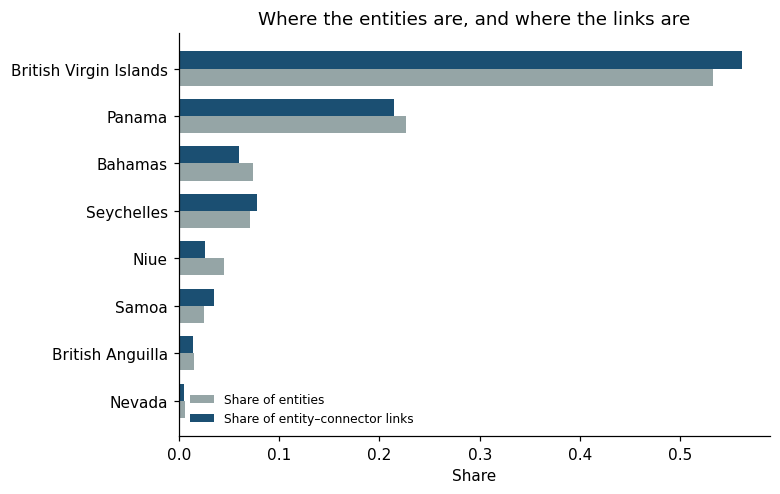

In [6]:
both = entB[["name", "jurisdiction", "degree", "pagerank", "betweenness"]].join(
    proj[["degree", "strength", "pagerank", "betweenness"]],
    how="left",
    lsuffix="_bip",
    rsuffix="_proj",
)
in_lcc = both["pagerank_proj"].notna()
print(f"Entities in the projection giant component: {int(in_lcc.sum()):,} / {len(both):,}")
top_bip = set(both.nlargest(20, "pagerank_bip").index)
top_proj = set(proj.nlargest(20, "pagerank").index)
print(f"Overlap of the top 20 PageRank entities, bipartite ∩ projection: {len(top_bip & top_proj)} / 20")
top_bip_deg = set(both.nlargest(20, "degree_bip").index)
top_proj_str = set(proj.nlargest(20, "strength").index)
print(f"Overlap of top 20 bipartite degree ∩ top 20 projection strength: {len(top_bip_deg & top_proj_str)} / 20")

common = both.loc[in_lcc]
rho_pp, _ = spearmanr(common["pagerank_bip"], common["pagerank_proj"])
rho_ds, _ = spearmanr(common["degree_bip"], common["strength"])
print(f"Spearman, entities in the component: bipartite PageRank vs projection PageRank = {rho_pp:.3f}")
print(f"Spearman, bipartite degree vs projection strength = {rho_ds:.3f}")

jur = entB.groupby("jurisdiction").agg(
    entities=("degree", "size"),
    degree_sum=("degree", "sum"),
    degree_mean=("degree", "mean"),
).sort_values("entities", ascending=False)
jur["share_of_entities"] = jur["entities"] / jur["entities"].sum()
jur["share_of_degree"] = jur["degree_sum"] / jur["degree_sum"].sum()
print("Jurisdictions by number of entities")
display(pretty(jur.head(12).reset_index(), sci=()))

top50 = entB.nlargest(50, "pagerank")
print("Jurisdictions of the 50 highest-PageRank entities (bipartite):")
print(top50["jurisdiction"].value_counts().to_string())

plotj = jur.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.2, 4.6))
y = np.arange(len(plotj))
ax.barh(y - 0.18, plotj["share_of_entities"], height=0.36, color="#95a5a6", label="Share of entities")
ax.barh(y + 0.18, plotj["share_of_degree"], height=0.36, color="#1b4f72", label="Share of entity–connector links")
ax.set_yticks(y, plotj.index.map(lambda s: short(s, 28)))
ax.set_xlabel("Share")
ax.set_title("Where the entities are, and where the links are")
ax.legend(frameon=False, fontsize=8)
savefig("03_jurisdiction_shares.png")

## 6. Same degree ranking, read from Neo4j

The database holds the same Panama Papers nodes. This cell recomputes intermediary degree in Cypher and checks it against the NetworkX ranking. PageRank and betweenness are not Graph Data Science procedures on this server (APOC core is installed, the algorithm library is not), so those two scores are calculated above in NetworkX and written back as `:CentralityScore` nodes for the dashboard.

In [7]:
from neo4j import GraphDatabase

uri, user, password, database = credentials()
driver = GraphDatabase.driver(uri, auth=(user, password))
driver.verify_connectivity()
cypher = (
    "MATCH (i:Intermediary)-[:INTERMEDIARY_OF]->(e:Entity) "
    "RETURN i.node_id AS node_id, i.name AS name, count(e) AS degree "
    "ORDER BY degree DESC LIMIT 12"
)
with driver.session(database=database) as session:
    neo = pd.DataFrame([dict(r) for r in session.run(cypher)])
nx_top = inter.nlargest(12, "degree")[["name", "degree"]].reset_index().rename(columns={"index": "node_id", "degree": "degree_networkx"})
cmp = neo.merge(nx_top, on="node_id", suffixes=("_neo4j", "_networkx"))
cmp["match"] = cmp["degree"] == cmp["degree_networkx"]
print(f"Top 12 intermediaries, Neo4j degree equals NetworkX degree: {bool(cmp['match'].all())} ({len(cmp)} rows matched on id).")
display(cmp[["name_neo4j", "degree", "degree_networkx", "match"]])

def records(df, graph, measure, kind, score, extra):
    top = df.nlargest(15, score)
    out = []
    for rank, (node_id, row) in enumerate(top.iterrows(), start=1):
        out.append({
            "id": f"{graph}|{measure}|{kind}|{rank}",
            "graph": graph,
            "measure": measure,
            "kind": kind,
            "rank": rank,
            "node_id": str(node_id),
            "name": None if pd.isna(row["name"]) else str(row["name"]),
            "score": float(row[score]),
            "extra": None if extra is None or pd.isna(row[extra]) else str(row[extra]),
        })
    return out

rows = []
rows += records(inter, "bipartite", "degree", "intermediary", "degree", "countries")
rows += records(inter, "bipartite", "pagerank", "intermediary", "pagerank", "countries")
rows += records(inter.dropna(subset=["betweenness"]), "bipartite", "betweenness", "intermediary", "betweenness", "countries")
rows += records(off, "bipartite", "degree", "officer", "degree", "countries")
rows += records(off, "bipartite", "pagerank", "officer", "pagerank", "countries")
rows += records(off.dropna(subset=["betweenness"]), "bipartite", "betweenness", "officer", "betweenness", "countries")
rows += records(entB, "bipartite", "degree", "entity", "degree", "jurisdiction")
rows += records(entB, "bipartite", "pagerank", "entity", "pagerank", "jurisdiction")
rows += records(entB.dropna(subset=["betweenness"]), "bipartite", "betweenness", "entity", "betweenness", "jurisdiction")
rows += records(proj, "projection", "degree", "entity", "degree", "jurisdiction")
rows += records(proj, "projection", "pagerank", "entity", "pagerank", "jurisdiction")
rows += records(proj, "projection", "betweenness", "entity", "betweenness", "jurisdiction")

write = (
    "UNWIND $rows AS row "
    "MERGE (n:CentralityScore {id: row.id}) "
    "SET n.graph = row.graph, n.measure = row.measure, n.kind = row.kind, n.rank = row.rank, "
    "n.node_id = row.node_id, n.name = row.name, n.score = row.score, n.extra = row.extra"
)
with driver.session(database=database) as session:
    session.run("MATCH (n:CentralityScore) DETACH DELETE n").consume()
    session.run(write, {"rows": rows}).consume()
    stored = session.run("MATCH (n:CentralityScore) RETURN count(n) AS n").single()["n"]
driver.close()
print(f"Wrote {stored} :CentralityScore nodes to {database} at {uri}.")

summary = {
    "bipartite_nodes": int(nB),
    "projection_lcc_nodes": int(nH),
    "k_bipartite": K_BIP,
    "k_projection": K_PROJ,
    "seed": SEED,
    "alpha": ALPHA,
    "top_intermediary": inter.nlargest(1, "degree")[["name", "countries", "degree", "pagerank", "betweenness"]].iloc[0].to_dict(),
    "top_officer": off.nlargest(1, "degree")[["name", "countries", "degree", "pagerank"]].iloc[0].to_dict(),
    "spearman_intermediary_degree_pagerank": float(spearmanr(inter["degree"], inter["pagerank"])[0]),
    "spearman_intermediary_degree_betweenness": float(rho_db),
    "spearman_intermediary_pagerank_betweenness": float(rho_pb),
    "jaccard15_intermediary_degree_pagerank": jaccard(inter, "degree", "pagerank", 15),
    "jaccard15_intermediary_degree_betweenness": jaccard(inter, "degree", "betweenness", 15),
    "pagerank_overlap_top20_bipartite_projection": len(top_bip & top_proj),
    "spearman_pagerank_bipartite_vs_projection": float(rho_pp),
    "jurisdiction_top": jur.head(5).reset_index()[["jurisdiction", "entities", "share_of_entities", "share_of_degree"]].to_dict(orient="records"),
}
def convert(obj):
    if isinstance(obj, dict):
        return {str(k): convert(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [convert(v) for v in obj]
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.integer,)):
        return int(obj)
    return obj
json.dump(convert(summary), open(PROC / "03_centrality_summary.json", "w"), indent=2)
inter.nlargest(15, "degree")[["name", "countries", "degree", "degree_centrality", "pagerank", "betweenness"]].to_csv(PROC / "03_top_intermediaries.csv")
print(json.dumps(convert(summary), indent=2)[:2500])

Top 12 intermediaries, Neo4j degree equals NetworkX degree: True (12 rows matched on id).


,name_neo4j,degree,degree_networkx,match
0,ORION HOUSE SERVICES (HK) LIMITED,7016,7016,True
1,MOSSACK FONSECA & CO.,4364,4364,True
2,PRIME CORPORATE SOLUTIONS SARL,4117,4117,True
3,OFFSHORE BUSINESS CONSULTANT (INT'L) LIMITED,4094,4094,True
4,MOSSACK FONSECA & CO. (SINGAPORE) PTE LTD.,3888,3888,True
5,CONSULCO INTERNATIONAL LIMITED,3168,3168,True
6,MOSSACK FONSECA & CO. (GENEVA) S.A.,2986,2986,True
7,MOSSACK FONSECA & CO. (U.K.) LIMITED,2538,2538,True
8,MOSSACK FONSECA & CO. (PERU) CORP.,2055,2055,True
9,"POWER POINT INT'L CO., LTD.",2045,2045,True


Wrote 180 :CentralityScore nodes to neo4j at bolt://localhost:7687.
{
  "bipartite_nodes": 468623,
  "projection_lcc_nodes": 26643,
  "k_bipartite": 50,
  "k_projection": 200,
  "seed": 0,
  "alpha": 0.85,
  "top_intermediary": {
    "name": "ORION HOUSE SERVICES (HK) LIMITED",
    "countries": "Hong Kong",
    "degree": 7016,
    "pagerank": 0.005767008329691226,
    "betweenness": 0.09773711056502936
  },
  "top_officer": {
    "name": "MOSSFON SUBSCRIBERS LTD.",
    "countries": "Samoa",
    "degree": 3882,
    "pagerank": 0.0025662873876873054
  },
  "spearman_intermediary_degree_pagerank": 0.922419542156148,
  "spearman_intermediary_degree_betweenness": 0.9652600908468238,
  "spearman_intermediary_pagerank_betweenness": 0.9683544673053,
  "jaccard15_intermediary_degree_pagerank": 1.0,
  "jaccard15_intermediary_degree_betweenness": 0.42857142857142855,
  "pagerank_overlap_top20_bipartite_projection": 0,
  "spearman_pagerank_bipartite_vs_projection": 0.0786427875287739,
  "jurisdict

## 7. What the ranks mean

The people who structure this network are a small set of corporate-service intermediaries, plus one nominee officer. Jurisdictions tell you where the companies are registered. They do not name the actors who hold the links.

**Volume.** Orion House Services (HK) Limited is linked to 7,016 entities. Its degree centrality is 7,016 / 468,622 = 0.015, and its PageRank is about 2,700 times the score of an average node. Mossack Fonseca & Co. in Panama is second by degree (4,364 entities). The top 15 intermediaries by degree and by PageRank are the same 15 names (Jaccard 1.00). Spearman correlation of the two scores across all intermediaries is 0.92. PageRank changes the order inside that list: Offshore Business Consultant (Hong Kong) is 2nd by PageRank and 4th by degree, and the Panama Mossack Fonseca office is 2nd by degree and 6th by PageRank.

**Paths.** With 50 sampled sources, betweenness puts Mossack Fonseca Singapore first and the UK office second. Orion House is third. Nine of the 15 highest-degree intermediaries are also in the betweenness top 15, and the rank correlation across all intermediaries in the giant component is 0.97. The order at the very top is the part that changes. Among officers, Mossfon Subscribers Ltd. (Samoa) is in a class of its own: degree 3,882, against 368 for the next officer, and estimated betweenness 0.70 against 0.05. In a bipartite graph every path between two entities goes through a connector, so a nominee attached to thousands of companies sits on a large share of those paths.

**Entities.** The highest-degree entity is Accelonic Ltd. (British Virgin Islands), degree 1,007, of which 1,006 neighbors are officers. Entity degree here is the size of an officer list. It is a different fact from an intermediary's client list.

**The two graphs.** On the entities that sit in the projection's giant component (26,643 companies, 12.5% of entities), bipartite PageRank and projection PageRank have Spearman correlation 0.08. The top 20 of each list share no names. The projection drops connectors above the cap, including every intermediary in the degree table above, so the companies those firms serve do not become a clique in the projection. Projection degree is led by Hacienda Property Holdings Ltd. (British Virgin Islands, 720 neighbors). Projection PageRank is led by a block of Bahamas companies with almost identical scores, which is what PageRank does inside one dense neighborhood. Use the bipartite graph to name the intermediaries. Use the projection to describe which entities share the smaller connectors.

**Jurisdictions.** The British Virgin Islands hold 53% of entities and 56% of entity–connector links. Panama holds 23% of entities and 21% of links. Niue holds 4.5% of entities and 2.6% of links. The registers are where the companies sit. The intermediaries that hold the links are in Hong Kong, Panama, Luxembourg, Singapore, Switzerland and the United Kingdom. Orion House's own clients are mostly in Seychelles (2,010), Samoa (1,984), the British Virgin Islands (1,669) and Anguilla (1,307). A Hong Kong firm is the largest organizer of companies registered elsewhere.

**Limit of the betweenness numbers.** Fifty sources are 0.016% of the giant component. The gap between Mossfon Subscribers and the next officer is large enough to report. A swap of two adjacent intermediaries in the middle of the betweenness list is not.